[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/08.%20Tree-Based%20Algorithms%20and%20Ensemble%20Methods/ch08_tree_based_ensembles.ipynb)

# Chapter 8: Tree-Based Algorithms and Ensemble Methods

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 8, pp. 210–235

**What you will learn in this chapter:**
- How a decision tree splits the data recursively (Gini impurity / entropy) and how to read a fitted tree
- How random forests use bagging (bootstrap aggregating) to reduce a single tree's variance, and how to read feature importances
- How gradient boosting builds trees sequentially, each one correcting the errors of the previous ones
- How to tune tree-based models (`max_depth`, `n_estimators`, `learning_rate`, …) with grid search and cross-validation
- How bagging, boosting and stacking compare, and why a single small test set cannot rank them
- Practical exercises: a decision tree, a tuned random forest, and gradient boosting vs random forest

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Decision trees | Recursive axis-aligned splits that make nodes purer | `DecisionTreeClassifier`, `plot_tree` |
| Random forests and bagging | Many trees on bootstrap samples + random feature subsets; average them | `RandomForestClassifier`, `BaggingClassifier` |
| Gradient boosting | Trees added one at a time, each fitting the previous residual errors | `GradientBoostingClassifier` |
| Hyper-parameter tuning | `max_depth`, `n_estimators`, `learning_rate`; grid vs random search | `GridSearchCV`, `RandomizedSearchCV` |
| Comparing ensembles | Bagging reduces variance, boosting reduces bias, stacking mixes models | `StackingClassifier` |
| Practical exercises | Tree, tuned forest, boosting vs forest | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).
The book's snippets omit some imports (`classification_report`, `matplotlib`); they are added here.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to decision trees

**Summary.** Decision trees are intuitive models for classification and regression. They recursively split the data on feature values, building a tree of **nodes** and **branches**: each internal node tests one feature, each **leaf** holds the predicted outcome.
They are popular for their interpretability and need no feature scaling.

### Getting ready — the Iris dataset

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
print(X_train.shape, X_test.shape, "| test class counts:", np.bincount(y_test))

(105, 4) (45, 4) | test class counts: [18 12 15]


### How to do it…

In [3]:
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

report = classification_report(
    y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.3f}")
styled_df

Accuracy: 0.867


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Verification against the book:** Figure 8.1 shows accuracy **0.867** with per-class precision 1.000 / 0.714 / 0.846 and recall 1.000 / 0.833 / 0.733 — reproduced above ✔ (support 18 / 12 / 15; 6 of the 45 test flowers are misclassified).

### How it works…
Decision trees split the data so as to increase the **homogeneity** (purity) of the resulting groups. The split criterion is **Gini impurity** (scikit-learn's default) or **entropy**. The book visualises the fitted tree with `plot_tree`:

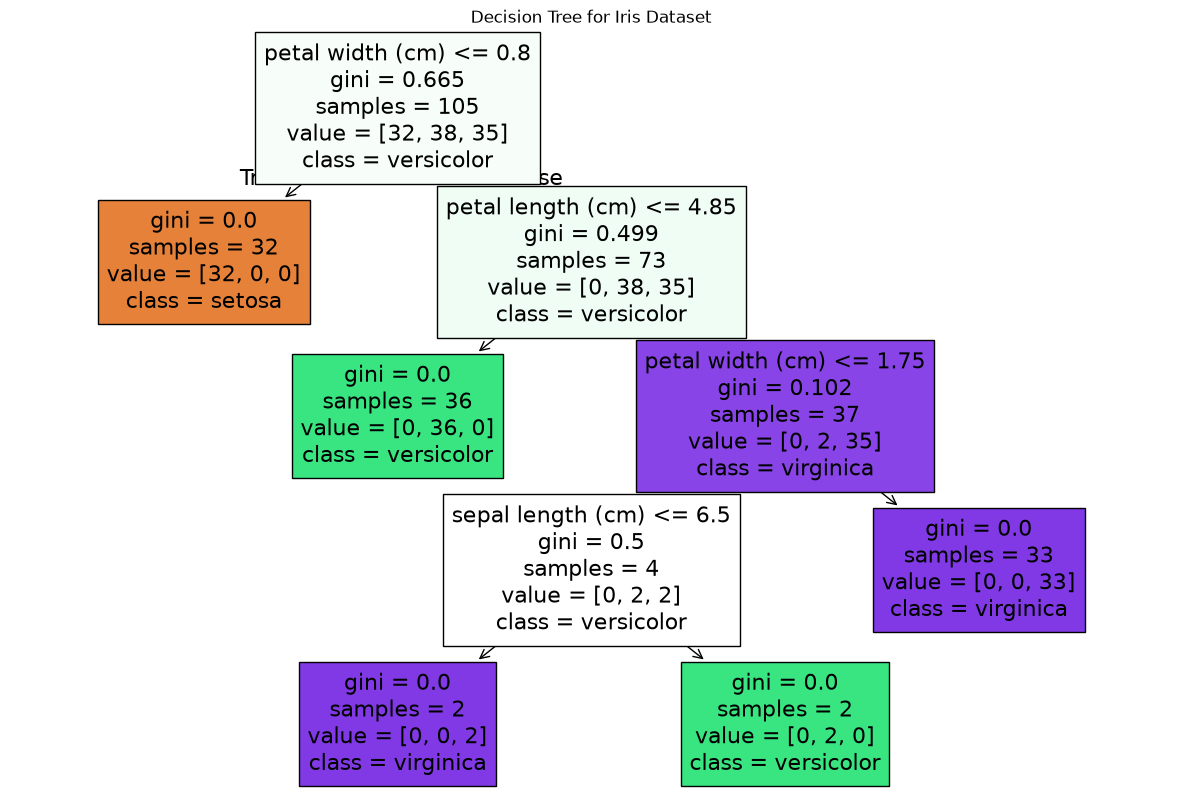

In [4]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))
plot_tree(clf, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True)
plt.title("Decision Tree for Iris Dataset")
plt.show()

> **Book correction (the printed code does not reproduce the book's figure).** The book's Figure 8.2 shows `samples = 100.0%` and `value = [0.305, 0.362, 0.333]` (proportions) in rounded boxes, and the text describes "samples" and "value" as *proportions*. But the code as printed
> (`plot_tree(clf, feature_names=..., class_names=..., filled=True)`) uses the defaults, which display **counts**: `samples = 105`, `value = [32, 38, 35]`. The figure was made with `proportion=True, rounded=True`:

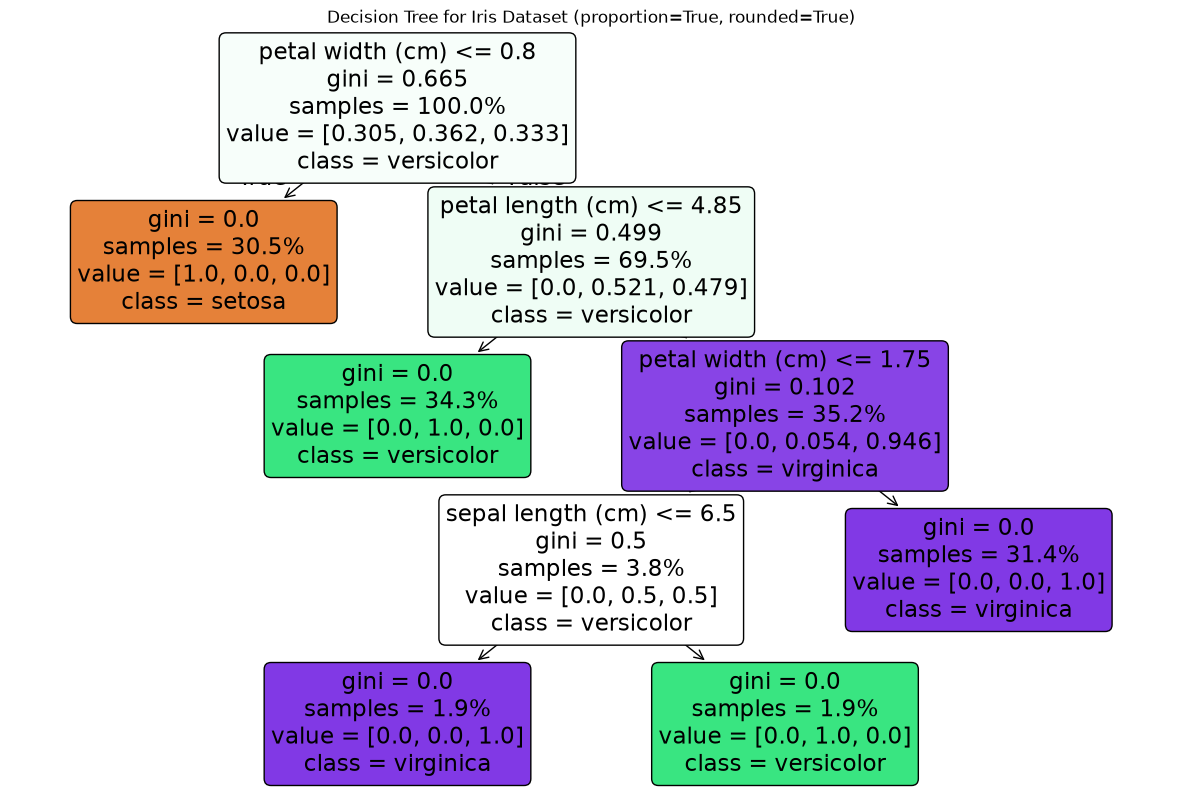

tree depth: 4 | leaves: 5 | nodes: 9
root node: feature = petal width (cm) | threshold = 0.8 | gini = 0.665 | class counts = [32. 38. 35.]


In [5]:
plt.figure(figsize=(15,10))
plot_tree(clf, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True,
          proportion=True, rounded=True)            # these two options reproduce the book's Figure 8.2
plt.title("Decision Tree for Iris Dataset (proportion=True, rounded=True)")
plt.show()

print("tree depth:", clf.get_depth(), "| leaves:", clf.get_n_leaves(), "| nodes:", clf.tree_.node_count)
print("root node: feature =", iris.feature_names[clf.tree_.feature[0]], "| threshold =", round(clf.tree_.threshold[0], 2),
      "| gini =", round(clf.tree_.impurity[0], 3), "| class counts =", clf.tree_.value[0, 0] * clf.tree_.n_node_samples[0])

**Verification against the book:** the tree has the book's structure — root split `petal width (cm) <= 0.8` with Gini **0.665**, then `petal length (cm) <= 4.85`, `petal width (cm) <= 1.75` and `sepal length (cm) <= 6.5`, depth **4** ("not counting the initial node … a depth of four"), 5 leaves ✔.

**Reading a node (book):**
* **Feature name and threshold** — e.g. `petal width <= 0.8`: records satisfying it go along the *True* edge (left), others along *False* (right). A node with no further split is a **leaf** (terminal node): the prediction is the class with the largest share in it (here a flower with petal width ≤ 0.8 is *setosa*).
* **Gini impurity** — how mixed the node is; 0 = pure. * **Samples** — the share (or count) of training records reaching the node. * **Value** — the class distribution in the node. * **Class** — the majority class.

> **Book correction (Gini range).** The book says "Gini values range from 0.0 to 1.0 … with **1.0 indicating an even balance of all classes**". Gini impurity is $1-\sum_k p_k^2$, so its maximum is $1-\frac1K$ — **0.5 for two classes, 0.667 for three** — it never reaches 1.0.
> The root node of this very tree has Gini 0.665, which *is* essentially the three-class maximum (0.667): the classes are almost perfectly balanced there.

**Extension — Gini, entropy and the best split computed by hand.** The root split should be the threshold (over all features) that most reduces the weighted impurity of the two children:

In [6]:
def gini(counts):
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = counts[counts > 0] / counts.sum()
    return -np.sum(p * np.log2(p))

root = np.bincount(y_train, minlength=3)
print("root class counts:", root, "| Gini =", round(gini(root), 4), "| entropy =", round(entropy(root), 4), "bits  (maximum for 3 classes: Gini 0.6667, entropy", round(np.log2(3), 4), ")")

# exhaustive search: every feature, every midpoint between consecutive distinct values
candidates_ = []
for j in range(X_train.shape[1]):
    vals = np.unique(X_train[:, j])
    for t in (vals[:-1] + vals[1:]) / 2:
        left, right = y_train[X_train[:, j] <= t], y_train[X_train[:, j] > t]
        w = (len(left) * gini(np.bincount(left, minlength=3)) + len(right) * gini(np.bincount(right, minlength=3))) / len(y_train)
        candidates_.append((w, j, t))
best_w = min(c[0] for c in candidates_)
ties = [(j, t) for w, j, t in candidates_ if w < best_w + 1e-12]
print(f"\nbest weighted child Gini over all splits: {best_w:.4f} (impurity decrease {gini(root) - best_w:.4f})")
print("splits that achieve it (exact ties):", [f"{iris.feature_names[j]} <= {t:.2f}" for j, t in ties])
print(f"split chosen by sklearn   : {iris.feature_names[clf.tree_.feature[0]]} <= {clf.tree_.threshold[0]:.2f}")

left = np.bincount(y_train[X_train[:, 3] <= 0.8], minlength=3); right = np.bincount(y_train[X_train[:, 3] > 0.8], minlength=3)
print("left child counts:", left, "(pure setosa, Gini", gini(left), ") | right child counts:", right, "(Gini", round(gini(right), 4), ")")

root class counts: [32 38 35] | Gini = 0.665 | entropy = 1.5814 bits  (maximum for 3 classes: Gini 0.6667, entropy 1.585 )

best weighted child Gini over all splits: 0.3470 (impurity decrease 0.3180)
splits that achieve it (exact ties): ['petal length (cm) <= 2.50', 'petal width (cm) <= 0.80']
split chosen by sklearn   : petal width (cm) <= 0.80
left child counts: [32  0  0] (pure setosa, Gini 0.0 ) | right child counts: [ 0 38 35] (Gini 0.4992 )


The brute-force search finds the best achievable weighted Gini (0.347), and **two different splits achieve it exactly**: `petal length <= 2.50` and `petal width <= 0.80` both isolate the 32 setosa flowers perfectly, so they give identical children. scikit-learn broke the tie in favour of petal width
(it examines features in a random order, controlled by `random_state`), which is why the book's tree starts with petal width — with another seed the root could be petal length. (For each feature, any threshold between the largest setosa value and the smallest versicolor value is equally good; scikit-learn takes the midpoint, here 0.8.)
That is the whole algorithm: **repeat this search in each child until a stopping rule is met**.

**Extension — following one flower down the tree, and the tree as rules:**

In [7]:
from sklearn.tree import export_text

sample = X_test[[0]]
node_ids = clf.decision_path(sample).indices
print("flower:", dict(zip(iris.feature_names, sample[0])), "-> predicted:", iris.target_names[clf.predict(sample)[0]], "| true:", iris.target_names[y_test[0]])
for n in node_ids:
    if clf.tree_.children_left[n] == clf.tree_.children_right[n]:
        print(f"  node {n}: LEAF  class counts {clf.tree_.value[n, 0] * clf.tree_.n_node_samples[n]}")
    else:
        f, t = clf.tree_.feature[n], clf.tree_.threshold[n]
        print(f"  node {n}: {iris.feature_names[f]} = {sample[0, f]:.2f} {'<=' if sample[0, f] <= t else '> '} {t:.2f}")
print()
print(export_text(clf, feature_names=iris.feature_names))

flower: {'sepal length (cm)': np.float64(5.8), 'sepal width (cm)': np.float64(4.0), 'petal length (cm)': np.float64(1.2), 'petal width (cm)': np.float64(0.2)} -> predicted: setosa | true: setosa
  node 0: petal width (cm) = 0.20 <= 0.80
  node 1: LEAF  class counts [32.  0.  0.]

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal length (cm) <= 4.85
|   |   |--- class: 1
|   |--- petal length (cm) >  4.85
|   |   |--- petal width (cm) <= 1.75
|   |   |   |--- sepal length (cm) <= 6.50
|   |   |   |   |--- class: 2
|   |   |   |--- sepal length (cm) >  6.50
|   |   |   |   |--- class: 1
|   |   |--- petal width (cm) >  1.75
|   |   |   |--- class: 2



### There's more… controlling complexity
Left unconstrained, a tree keeps splitting until every training sample is in a pure leaf — a highly overfit model. The book lists the hyper-parameters that limit this:
* **`max_depth`** — maximum number of split levels (complexity vs purity). * **`min_samples_split`** — do not split a node with fewer samples than this. * **`min_samples_leaf`** — a split must leave at least this many samples in each child.
* **`max_features`** — number of features examined at each split (default `None` = all for a single tree). * **`min_impurity_decrease`** — only split if impurity falls by at least this much.

**Extension — what each one does**, on the *Breast Cancer* data (569 samples), with 5-fold cross-validation:

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score, StratifiedKFold

Xb, yb = load_breast_cancer(return_X_y=True)
cv = StratifiedKFold(5, shuffle=True, random_state=2024)
configs = {
    "default (no limits)":              dict(),
    "max_depth=3":                      dict(max_depth=3),
    "min_samples_split=40":             dict(min_samples_split=40),
    "min_samples_leaf=10":              dict(min_samples_leaf=10),
    "max_features='sqrt'":              dict(max_features="sqrt"),
    "min_impurity_decrease=0.01":       dict(min_impurity_decrease=0.01),
    "max_depth=3 + min_samples_leaf=5": dict(max_depth=3, min_samples_leaf=5),
}
rows = []
for name, kw in configs.items():
    m = DecisionTreeClassifier(random_state=2024, **kw)
    s = cross_val_score(m, Xb, yb, cv=cv); m.fit(Xb, yb)
    rows.append({"setting": name, "depth": m.get_depth(), "leaves": m.get_n_leaves(), "train acc": m.score(Xb, yb), "CV acc": s.mean(), "CV sd": s.std()})
pd.DataFrame(rows).set_index("setting").round(3)

,depth,leaves,train acc,CV acc,CV sd
setting,,,,,
default (no limits),7,22,1.000,0.940,0.029
max_depth=3,3,8,0.979,0.924,0.021
min_samples_split=40,6,11,0.965,0.919,0.028
min_samples_leaf=10,6,11,0.961,0.917,0.038
max_features='sqrt',9,28,1.000,0.931,0.025
min_impurity_decrease=0.01,3,6,0.975,0.930,0.022
max_depth=3 + min_samples_leaf=5,3,8,0.975,0.926,0.023


The unconstrained tree has 100 % training accuracy and 22 leaves, and — perhaps surprisingly — the **highest cross-validated accuracy of the table (0.940)**; the constrained trees score 0.917–0.931, i.e. 1–2 points lower, which is within one fold-to-fold standard deviation (0.02–0.04). What the limits buy is **simplicity**: 6–11 leaves instead of 22
(`max_depth=3` gives a tree of 8 leaves that can be read in seconds) for a small, statistically insignificant loss. On a dataset this clean a single tree's overfitting costs little accuracy; it shows mainly as the gap between training (1.000) and cross-validated (0.94) accuracy, and as an uninterpretable model.

**Extension — the overfitting curve: accuracy against `max_depth`.**

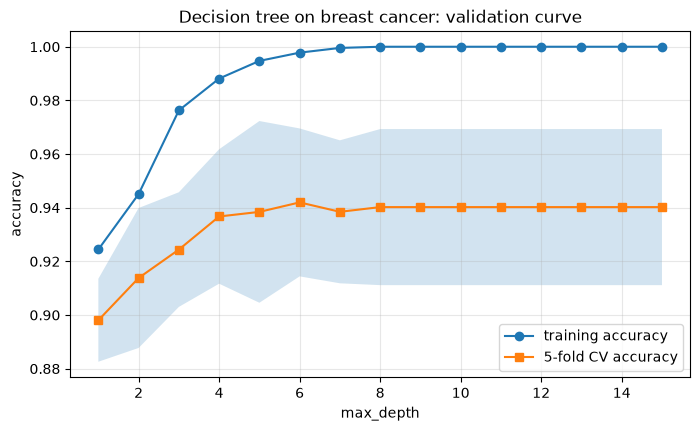

best max_depth by CV: 6 | CV accuracy 0.942 | unconstrained tree CV accuracy 0.94


In [9]:
from sklearn.model_selection import validation_curve

depths = np.arange(1, 16)
tr, te = validation_curve(DecisionTreeClassifier(random_state=2024), Xb, yb, param_name="max_depth", param_range=depths, cv=cv)
plt.figure(figsize=(8, 4.5))
plt.plot(depths, tr.mean(axis=1), "o-", label="training accuracy"); plt.plot(depths, te.mean(axis=1), "s-", label="5-fold CV accuracy")
plt.fill_between(depths, te.mean(axis=1) - te.std(axis=1), te.mean(axis=1) + te.std(axis=1), alpha=.2)
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.title("Decision tree on breast cancer: validation curve"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("best max_depth by CV:", depths[te.mean(axis=1).argmax()], "| CV accuracy", round(te.mean(axis=1).max(), 3), "| unconstrained tree CV accuracy", round(te.mean(axis=1)[-1], 3))

Training accuracy climbs to 1.0 by depth 8 while the CV accuracy rises to a peak at depth 6 (0.942) and then stays flat at 0.940 — it does **not** fall afterwards, because this tree cannot grow deeper than depth 7 (all leaves are pure by then), so the curve simply stops changing.
The overfitting is the persistent **gap** between the two curves (1.00 vs 0.94). Reading it as the book later describes for *validation curves*: low train and low validation = underfit (depth 1–2); high train with a clearly lower validation score = the model is fitting noise.

**Extension — post-pruning with cost-complexity (`ccp_alpha`).** Instead of stopping early, grow the full tree and then prune the weakest branches:

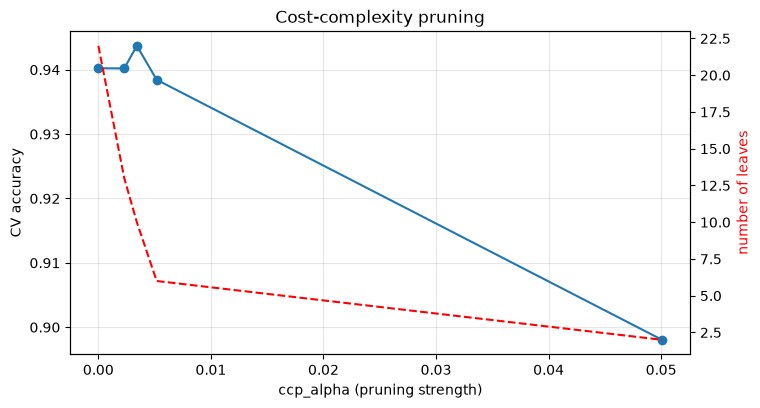

best ccp_alpha = 0.0034: CV accuracy 0.944 with 10 leaves (full tree: 22 leaves)


In [10]:
path = DecisionTreeClassifier(random_state=2024).fit(Xb, yb).cost_complexity_pruning_path(Xb, yb)
alphas = path.ccp_alphas[:-1][::3]
scores = [cross_val_score(DecisionTreeClassifier(random_state=2024, ccp_alpha=a), Xb, yb, cv=cv).mean() for a in alphas]
leaves = [DecisionTreeClassifier(random_state=2024, ccp_alpha=a).fit(Xb, yb).get_n_leaves() for a in alphas]
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.plot(alphas, scores, "o-"); ax.set_xlabel("ccp_alpha (pruning strength)"); ax.set_ylabel("CV accuracy"); ax.grid(alpha=.3)
ax2 = ax.twinx(); ax2.plot(alphas, leaves, "r--", label="leaves"); ax2.set_ylabel("number of leaves", color="r"); plt.title("Cost-complexity pruning"); plt.show()
i = int(np.argmax(scores)); print(f"best ccp_alpha = {alphas[i]:.4f}: CV accuracy {scores[i]:.3f} with {leaves[i]} leaves (full tree: {leaves[0]} leaves)")

**Extension — trees for regression, scale invariance, missing values, categorical data.** The chapter intro says trees do "classification and regression" and "handle numerical and categorical data". Checking each:

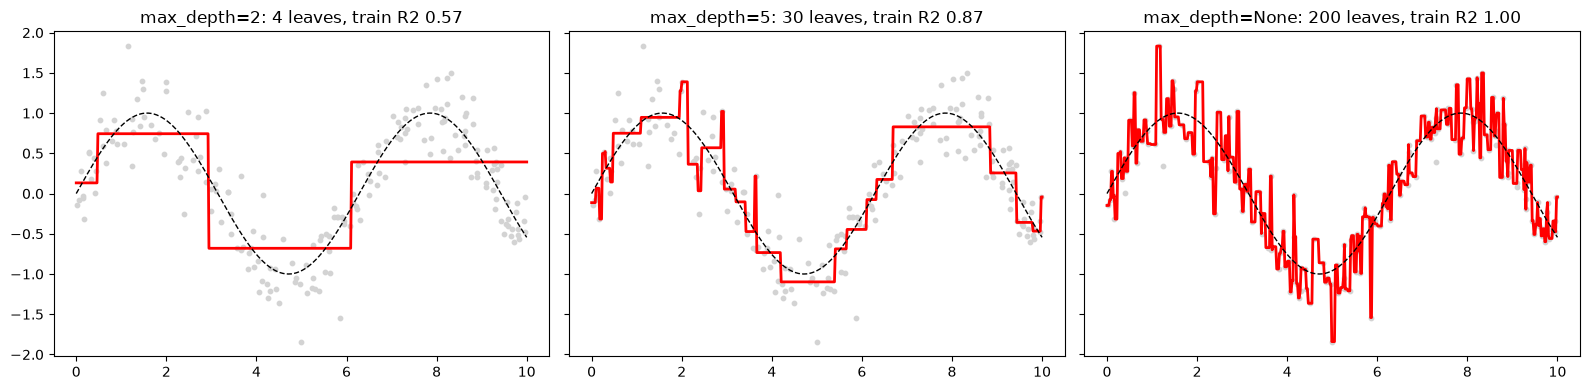

predictions identical on standardised features: True
DecisionTreeClassifier accepts NaN in this scikit-learn version
string categories -> ValueError: could not convert string to float: 'red'


In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler

# 1) regression: a piecewise-constant fit to a noisy sine wave
rng = np.random.default_rng(0)
xr = np.sort(rng.uniform(0, 10, 200))[:, None]; yr = np.sin(xr[:, 0]) + rng.normal(0, 0.3, 200)
grid = np.linspace(0, 10, 500)[:, None]
fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, d in zip(ax, (2, 5, None)):
    m = DecisionTreeRegressor(max_depth=d, random_state=0).fit(xr, yr)
    a.scatter(xr, yr, s=10, c="lightgrey"); a.plot(grid, m.predict(grid), "r", lw=2); a.plot(grid, np.sin(grid[:, 0]), "k--", lw=1)
    a.set_title(f"max_depth={d}: {m.get_n_leaves()} leaves, train R2 {m.score(xr, yr):.2f}")
plt.tight_layout(); plt.show()

# 2) trees are invariant to monotonic rescaling of features
Xs_tr = StandardScaler().fit(X_train).transform(X_train); Xs_te = StandardScaler().fit(X_train).transform(X_test)
same = (DecisionTreeClassifier(random_state=2024).fit(Xs_tr, y_train).predict(Xs_te) == clf.predict(X_test)).all()
print("predictions identical on standardised features:", same)

# 3) missing values (recent scikit-learn versions)
Xn = X_train.copy(); Xn[::7, 2] = np.nan
try:
    DecisionTreeClassifier(random_state=0).fit(Xn, y_train); print("DecisionTreeClassifier accepts NaN in this scikit-learn version")
except ValueError as e:
    print("NaN not supported here:", str(e)[:80])

# 4) categorical data given as text
try:
    DecisionTreeClassifier().fit(np.array([["red", 1], ["blue", 2], ["red", 3], ["blue", 4]], dtype=object), [0, 1, 0, 1])
except ValueError as e:
    print("string categories ->", type(e).__name__ + ":", str(e)[:70])

A regression tree predicts the **mean of the training targets in each leaf**, so its fit is a staircase (piecewise constant): depth 2 under-fits, unrestricted depth interpolates the noise. Rescaling features changes nothing (splits depend on order, not magnitude). Recent versions accept NaN natively.

> **Book correction (categorical data).** The book says trees are "popular due to their … effectiveness in handling both numerical and categorical data". The *algorithm* can, but **scikit-learn's `DecisionTreeClassifier` requires numeric input** — text categories raise an error (as above) and must be one-hot or ordinal encoded first (Chapter 2).
> Native categorical support in scikit-learn exists only in the histogram gradient-boosting models (`HistGradientBoosting*`, `categorical_features=`).

### Theory
* **CART algorithm.** Greedy, top-down, recursive: at each node choose the (feature, threshold) pair maximising the impurity decrease $\Delta I=I(\text{parent})-\sum_{c\in\{L,R\}}\frac{n_c}{n}I(c)$, then recurse on the children until a stopping rule applies (pure node, `max_depth`, `min_samples_*`, …).
* **Impurity measures.** Gini $=1-\sum_kp_k^2$ (max $1-1/K$); entropy $=-\sum_kp_k\log_2p_k$ (max $\log_2K$); for regression the variance / MSE of the node. They almost always pick very similar splits.
* **Characteristics.** Boundaries are **axis-aligned** and piecewise constant; no scaling needed; interpretable; but **high variance** (small data changes can give a very different tree) and prone to overfitting — the motivation for ensembles.
* **Feature importance (MDI).** The total impurity decrease attributed to a feature, summed over its splits (normalised): `feature_importances_`.
* **Complexity control:** pre-pruning (`max_depth`, `min_samples_*`, `min_impurity_decrease`) or post-pruning (`ccp_alpha`); choose by cross-validation.

### Hands-on workflow (from the book)
Choose a classification dataset → split → `DecisionTreeClassifier` → `fit` → `predict` → accuracy and confusion matrix → visualise the tree and interpret the splits (all done above).

## 2. Random forests and bagging

**Summary.** A single tree is intuitive but overfits. A **random forest** combines many trees to improve accuracy and reduce overfitting. It uses **bagging** (*bootstrap aggregating*): each tree is trained on a different sample of the data drawn **with replacement**, and the trees' predictions are combined
(majority vote or average). In addition, each split considers only a random subset of features, which decorrelates the trees.

### Getting ready

In [12]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report     # (classification_report is missing from the book's import list)

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…

In [13]:
rf_clf = RandomForestClassifier(
    n_estimators=100, random_state=2024)
rf_clf.fit(X_train, y_train)
y_pred = rf_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(
    y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.3f}")
styled_df

Accuracy: 0.911


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.833,0.833,0.833,12
2,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


**Verification against the book:** Figure 8.3 shows accuracy **0.911** (class 1: precision/recall 0.833; class 2: 0.867) and the text says "our single decision tree reported an accuracy of 0.867, while our random forest's accuracy is 0.911" — reproduced ✔.
That is **4 mistakes instead of 6 out of 45 test flowers** — a difference of 2 samples. We will check with cross-validation below whether it is real.

### How it works…
Each tree is trained on a bootstrap sample, and at each split a random subset of features is considered, adding diversity; averaging reduces variance and improves generalisation. The book then plots the **feature importances**:

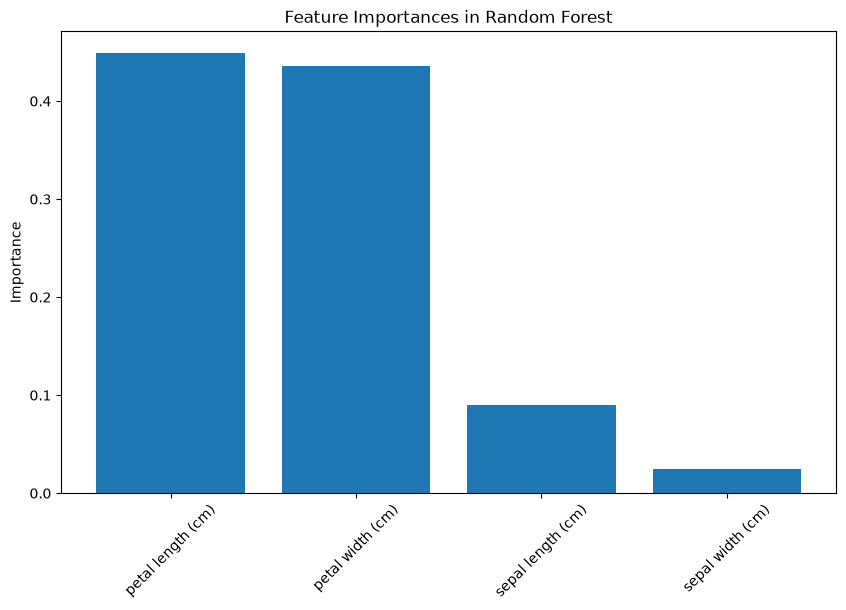

{'petal length (cm)': np.float64(0.449), 'petal width (cm)': np.float64(0.436), 'sepal length (cm)': np.float64(0.09), 'sepal width (cm)': np.float64(0.025)}


In [14]:
import matplotlib.pyplot as plt

importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("Feature Importances in Random Forest")
plt.bar(range(X.shape[1]),
        importances[indices], align="center")
plt.xticks(range(X.shape[1]),
           [iris.feature_names[i] for i in indices],
           rotation=45)
plt.ylabel("Importance")
plt.show()
print(dict(zip([iris.feature_names[i] for i in indices], importances[indices].round(3))))

As the book says, petal length and petal width dominate (together ≈ 85–90 %). The book adds that forests are sometimes used **only for feature selection** — the important features are then passed to another model.

**Extension — how a forest works, built by hand.** Train 100 trees on bootstrap samples and average their *probabilities*; compare with `RandomForestClassifier`. (Verifying also that the forest averages class **probabilities** — soft voting — rather than counting hard votes.)

In [15]:
from sklearn.tree import DecisionTreeClassifier

# soft voting: the forest's probability is the mean of its trees' probabilities
tree_probs = np.mean([t.predict_proba(X_test) for t in rf_clf.estimators_], axis=0)
print("rf.predict_proba == mean of the trees' predict_proba:", np.allclose(tree_probs, rf_clf.predict_proba(X_test)))
hard = np.array([t.predict(X_test) for t in rf_clf.estimators_]).astype(int)
majority = np.array([np.bincount(hard[:, i], minlength=3).argmax() for i in range(hard.shape[1])])
print("hard majority vote agrees with rf.predict on", f"{(majority == rf_clf.predict(X_test)).mean():.1%}", "of test points")

# a forest from scratch: bootstrap samples + random feature subsets at every split (max_features='sqrt')
rng = np.random.default_rng(0); trees = []
for b in range(100):
    idx = rng.integers(0, len(X_train), len(X_train))                      # sample WITH replacement
    trees.append(DecisionTreeClassifier(max_features="sqrt", random_state=b).fit(X_train[idx], y_train[idx]))
manual = np.mean([t.predict_proba(X_test) for t in trees], axis=0).argmax(axis=1)
single = [t.score(X_test, y_test) for t in trees]
print(f"\nindividual trees' test accuracy: mean {np.mean(single):.3f}, min {np.min(single):.3f}, max {np.max(single):.3f}")
print(f"manual forest (100 trees averaged): {accuracy_score(y_test, manual):.3f} | sklearn RandomForestClassifier: {rf_clf.score(X_test, y_test):.3f}")
print("share of unique samples in one bootstrap sample:", round(len(np.unique(rng.integers(0, 105, 105))) / 105, 3), "(theory: 1 - 1/e = 0.632)")

rf.predict_proba == mean of the trees' predict_proba: True
hard majority vote agrees with rf.predict on 100.0% of test points



individual trees' test accuracy: mean 0.895, min 0.800, max 0.978
manual forest (100 trees averaged): 0.911 | sklearn RandomForestClassifier: 0.911
share of unique samples in one bootstrap sample: 0.638 (theory: 1 - 1/e = 0.632)


The averaged forest is more accurate than the typical individual tree, and the bootstrap sample contains only ≈ 63 % of the distinct training points — the other ≈ 37 % ("out-of-bag") are never seen by that tree, which gives a free validation set (next).

**Extension — is the forest really better than one tree? Repeated cross-validation, plus the out-of-bag estimate and the effect of the number of trees.** Breast Cancer (569 samples) gives much more reliable numbers than 45 Iris flowers:

In [16]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
models = {
    "single decision tree": DecisionTreeClassifier(random_state=2024),
    "Bagging of 100 trees (all features)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=2024),
    "Random forest (100 trees, sqrt features)": RandomForestClassifier(n_estimators=100, random_state=2024),
    "Extra-trees (100 trees)": ExtraTreesClassifier(n_estimators=100, random_state=2024),
}
rows = {}
for name, m in models.items():
    for dname, (Xd, yd) in {"Iris": (X, y), "Breast cancer": (Xb, yb)}.items():
        s = cross_val_score(m, Xd, yd, cv=rcv); rows.setdefault(name, {})[dname + ": CV mean"] = s.mean(); rows[name][dname + ": sd"] = s.std()
pd.DataFrame(rows).T.round(3)

,Iris: CV mean,Iris: sd,Breast cancer: CV mean,Breast cancer: sd
single decision tree,0.956,0.020,0.934,0.020
Bagging of 100 trees (all features),0.956,0.031,0.957,0.022
"Random forest (100 trees, sqrt features)",0.953,0.036,0.960,0.017
Extra-trees (100 trees),0.953,0.036,0.969,0.012


The two datasets tell different stories. On **Breast Cancer** (569 samples) every ensemble beats the single tree: 0.934 → 0.957 (bagging), 0.960 (forest), 0.969 (extra-trees), i.e. +2.3 to +3.5 points, more than one standard deviation (0.012–0.022). On **Iris** there is **no gain at all**: the single tree scores 0.956, bagging 0.956, the forest and
extra-trees 0.953 — all identical within noise (sd 0.02–0.04). So the book's headline "0.867 → 0.911, we improved quite a bit" on Iris was **a lucky/unlucky split, not a real effect**: averaged over 15 splits the single tree is as good as the forest (and its accuracy, 0.956, is far above the 0.867 of that one split).
On the larger Breast Cancer data plain **bagging** of full trees already captures most of the gain; the random feature subset (**random forest**) and extra randomisation (**extra-trees**) decorrelate the trees a little further.

out-of-bag accuracy (no validation set needed): 0.9649 | 5-fold CV accuracy: 0.9578


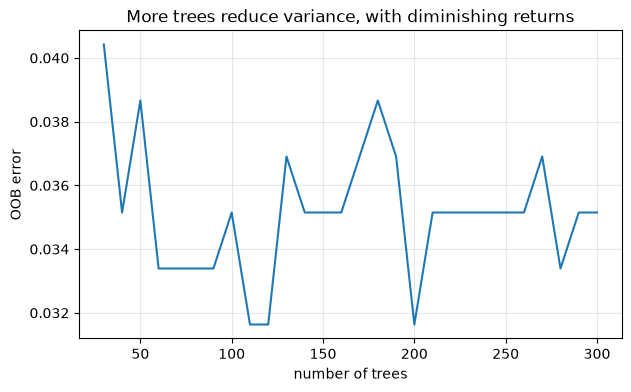

In [17]:
rf_oob = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=2024, bootstrap=True).fit(Xb, yb)
print("out-of-bag accuracy (no validation set needed):", round(rf_oob.oob_score_, 4), "| 5-fold CV accuracy:", round(cross_val_score(RandomForestClassifier(n_estimators=300, random_state=2024), Xb, yb, cv=cv).mean(), 4))

# OOB error as trees are added (warm_start grows the same forest)
rf_w = RandomForestClassifier(oob_score=True, warm_start=True, random_state=2024, n_estimators=1)
ns, errs = [], []
for n in list(range(30, 301, 10)):                    # (fewer than ~30 trees leave some samples without any out-of-bag prediction)
    rf_w.set_params(n_estimators=n); rf_w.fit(Xb, yb); ns.append(n); errs.append(1 - rf_w.oob_score_)
plt.figure(figsize=(7, 4)); plt.plot(ns, errs); plt.xlabel("number of trees"); plt.ylabel("OOB error"); plt.title("More trees reduce variance, with diminishing returns"); plt.grid(alpha=.3); plt.show()

The out-of-bag accuracy (0.965) agrees with the cross-validated accuracy (0.958) without holding anything out. The OOB error falls from ≈ 0.040 at 30 trees to ≈ 0.034 by about 60 trees and then **fluctuates between 0.032 and 0.039** (the jitter is ±2–3 of the 569 samples, i.e. noise): the improvement flattens after roughly 60 trees and
more trees do not make it worse — adding trees to a forest does not cause overfitting in the usual sense, it only costs time and memory.

**Extension — how trustworthy are the importances?** The book's importance (mean decrease in impurity, **MDI**) is computed on the *training* data (and is known to favour features with many distinct values). **Permutation importance** on held-out data shuffles one feature and measures the drop in accuracy.
Test on Breast Cancer: append three columns of pure noise and compare the two.

In [18]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(1)
Xn = np.c_[Xb, rng.normal(size=(len(Xb), 3))]                              # 3 pure-noise columns appended
names = list(load_breast_cancer().feature_names) + ["NOISE_1", "NOISE_2", "NOISE_3"]
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yb, test_size=0.3, random_state=2024, stratify=yb)
rfn = RandomForestClassifier(n_estimators=300, random_state=2024).fit(Xn_tr, yn_tr)
mdi = pd.Series(rfn.feature_importances_, index=names)
perm = pd.Series(permutation_importance(rfn, Xn_te, yn_te, n_repeats=20, random_state=0).importances_mean, index=names)
cmp_ = pd.DataFrame({"MDI (training data)": mdi, "permutation (held-out data)": perm})
display(cmp_.sort_values("MDI (training data)", ascending=False).head(6).round(4))
print("NOISE columns -> MDI:", mdi[-3:].round(4).tolist(), "| permutation:", perm[-3:].round(4).tolist())
print("rank of the noise columns by MDI (1 = most important of 33):", [int(mdi.rank(ascending=False)[n]) for n in names[-3:]])

,MDI (training data),permutation (held-out data)
worst concave points,0.1247,-0.0108
worst radius,0.1098,0.0023
worst perimeter,0.1087,-0.0026
mean concave points,0.0977,-0.0111
worst area,0.0943,-0.0003
mean concavity,0.0662,-0.0099


NOISE columns -> MDI: [0.0028, 0.0028, 0.0024] | permutation: [0.0009, 0.0, 0.0]
rank of the noise columns by MDI (1 = most important of 33): [31, 32, 33]


What the test shows — and does not show:
* **MDI** gives the three pure-noise columns small but **non-zero** importance (≈ 0.003 each: they get used for splits that fit training noise) — but it still ranks them **last** (31st–33rd of 33). The bias towards noisy high-cardinality features is therefore *not* dramatic here with Gaussian noise.
* **Permutation importance** on held-out data puts the noise at ≈ 0 (0.0009, 0, 0), as it should — but it also gives ≈ 0, and even *slightly negative* values, to the genuinely important features (`worst concave points` −0.011, `worst radius` +0.002, `worst perimeter` −0.003). The reason is **correlated features**:
  radius, perimeter and area (and their "mean"/"worst" versions) are near-duplicates, so shuffling one leaves its twins to carry the signal and the accuracy barely drops.
* So **neither importance is a clean ground truth**: MDI slightly rewards noise, permutation importance *understates* redundant features. For correlated data use grouped permutation (shuffle a whole group of related columns), drop redundant columns first, or compare several methods.

### There's more… (book)
Hyper-parameters such as `max_features`, `max_depth` and `n_estimators` can be tuned, and **bagging** can be applied to other models with `BaggingClassifier()` / `BaggingRegressor()` — shown above with a decision tree; with a stable model such as k-NN the gain from bagging is much smaller (bagging helps *unstable*, high-variance learners).

### Theory
* **Bagging:** train $B$ models on bootstrap resamples and average them. If each has variance $\sigma^2$ and pairwise correlation $\rho$, the average has variance $\rho\sigma^2+\frac{1-\rho}{B}\sigma^2$: averaging removes the second term, so **decorrelating the trees** (random feature subsets) lowers the first.
  Bias is roughly unchanged, so bagging fixes *variance* — hence it needs deep, low-bias trees.
* **Random forest = bagging + random feature subsets** (`max_features='sqrt'` for classification by default). **Extra-trees** also draws the split thresholds at random.
* **Out-of-bag (OOB) samples:** each tree sees ≈ 63.2 % of the data; predicting each sample with only the trees that did not train on it gives an honest validation estimate for free (`oob_score=True`).
* **Combination rule:** scikit-learn's forest averages the trees' class **probabilities** (soft voting) — slightly different from the "majority vote" in the book's description.
* **Strengths/weaknesses:** accurate with little tuning, robust to outliers and irrelevant features, handles interactions; less interpretable than one tree, larger and slower at prediction, extrapolates poorly (regression predictions stay inside the training range).

### Hands-on workflow (from the book)
Classification dataset → split → `RandomForestClassifier` → `fit` → `predict` → accuracy/precision/recall → feature importances (done above, plus a from-scratch forest, the OOB score and permutation importance).

## 3. Gradient boosting machines

**Summary.** Gradient boosting machines (GBMs) build an ensemble **sequentially**: each new (shallow) tree is trained to correct the errors of the ensemble so far. Random forests build trees in *parallel* and average them (reducing variance); GBMs build them *one after another* and add them (reducing bias).
"Boosting" means boosting the performance of each successive tree.

### Getting ready

In [19]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…
The book uses 1 000 trees and a learning rate of 0.2.

In [20]:
import time
t0 = time.time()
gbm_clf = GradientBoostingClassifier(
    n_estimators=1000,
    learning_rate=0.2,
    random_state=2024
)
gbm_clf.fit(X_train, y_train)
fit_time = time.time() - t0
y_pred = gbm_clf.predict(X_test)

report = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)).transpose()

styled_df = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}   (fit time {fit_time:.1f}s)")
styled_df

Accuracy: 0.867   (fit time 2.4s)


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Verification against the book:** Figure 8.5 shows exactly the same report as the single decision tree — accuracy **0.867**, class 1 precision/recall 0.714 / 0.833, class 2 0.846 / 0.733 — reproduced ✔ (the same 6 flowers are misclassified).

The book comments that the identical result "could mean that both the decision tree and GBM approaches are overfitting our data and have reached a local maximum with their predictive performance". Let us look closer:

In [21]:
print("training accuracy of the GBM:", gbm_clf.score(X_train, y_train), "| test accuracy:", round(gbm_clf.score(X_test, y_test), 4))
print("trees actually stored:", gbm_clf.estimators_.shape, "-> (iterations, one tree per class) = 1000 x 3 = 3000 regression trees")
wrong_dt = set(np.where(clf.predict(X_test) != y_test)[0]); wrong_gb = set(np.where(y_pred != y_test)[0])
print("misclassified test flowers: decision tree", sorted(wrong_dt), "| GBM", sorted(wrong_gb), "-> identical:", wrong_dt == wrong_gb)

training accuracy of the GBM: 1.0 | test accuracy: 0.8667
trees actually stored: (1000, 3) -> (iterations, one tree per class) = 1000 x 3 = 3000 regression trees
misclassified test flowers: decision tree [np.int64(3), np.int64(10), np.int64(17), np.int64(26), np.int64(35), np.int64(38)] | GBM [np.int64(3), np.int64(10), np.int64(17), np.int64(26), np.int64(35), np.int64(38)] -> identical: True


Both models classify the training set perfectly (train accuracy 1.0) and make the **same six mistakes** on the test set — those flowers sit in the versicolor/virginica overlap and are hard for any model. "Local maximum" is the wrong term (that describes an optimiser, not accuracy);
the plain explanation is that Iris has a small irreducible overlap and the 45-point test set cannot distinguish models that differ by a sample or two. (Also, for 3 classes the GBM trains **one tree per class per iteration**, so 1 000 iterations = 3 000 trees.)

### How it works…
GBMs add models that predict the **residuals** (errors) of the current ensemble: start from a simple initial prediction, then at each iteration fit a small tree to the residuals and add a fraction (`learning_rate`) of its output. **Extension — gradient boosting for regression written from scratch** (each tree fits the current residuals), checked against `GradientBoostingRegressor`:

In [22]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(0)
xs = np.sort(rng.uniform(0, 10, 150))[:, None]; ys = np.sin(xs[:, 0]) + 0.3 * xs[:, 0] + rng.normal(0, 0.25, 150)
lr, M = 0.2, 60

pred = np.full(len(ys), ys.mean())                    # initial simple prediction: the mean
trees = []
for m in range(M):
    residual = ys - pred                              # what the ensemble still gets wrong (the negative gradient of the squared error)
    tree = DecisionTreeRegressor(max_depth=2, criterion="squared_error", random_state=0).fit(xs, residual)
    pred += lr * tree.predict(xs); trees.append(tree)
    if m in (0, 4, 19, 59): print(f"after {m + 1:2d} trees: training MSE = {np.mean((ys - pred) ** 2):.4f}")

ref = GradientBoostingRegressor(n_estimators=M, learning_rate=lr, max_depth=2, random_state=0).fit(xs, ys)
print("\nmax |manual - GradientBoostingRegressor| on the training points:", np.abs(pred - ref.predict(xs)).max())

after  1 trees: training MSE = 0.8694
after  5 trees: training MSE = 0.2654
after 20 trees: training MSE = 0.0603
after 60 trees: training MSE = 0.0338

max |manual - GradientBoostingRegressor| on the training points: 0.0


The hand-written loop reproduces scikit-learn exactly: the training error falls with every added tree because each tree is aimed at what is still wrong. For classification the "residual" is the gradient of the log-loss (the difference between the label and the predicted probability), computed per class.

### There's more… (book): early stopping and validation curves
The book gives two tools: **early stopping** — "limiting the iterative fitting process to avoid overfitting" — and **validation curves** — plotting train vs validation scores against a hyper-parameter (low/low = underfit; high train, low validation = overfit).

> **Book correction (early stopping).** The book illustrates early stopping with *tree* constraints ("if we don't constrain the training process using hyperparameters, the tree will be built until all samples are in terminal nodes … adjusting the hyperparameters effectively stops the fitting process early"). That is **pre-pruning**
> (`max_depth`, `min_samples_*`), a different thing. **Early stopping** in boosting means stopping the *boosting iterations* when the score on a held-out validation set stops improving — in scikit-learn via `n_iter_no_change` / `validation_fraction`.

**Extension — the staged score curve, the learning-rate / number-of-trees trade-off, and real early stopping** on Breast Cancer:

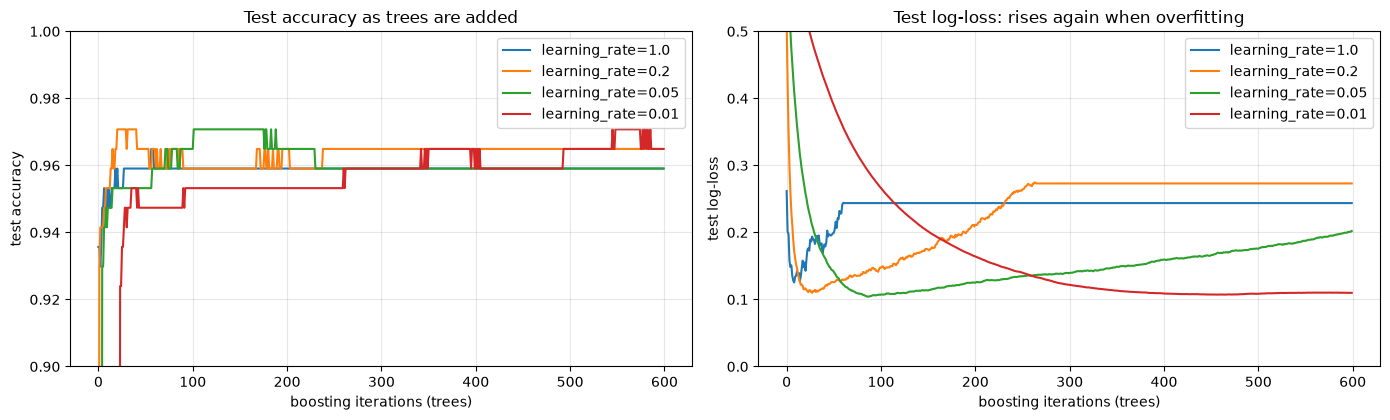

,test acc @50 trees,@200,@600,best test acc,best at tree #,min test log-loss,at tree #
learning_rate,,,,,,,
1.00,0.959,0.959,0.959,0.965,57,0.125,9
0.20,0.965,0.965,0.965,0.971,21,0.110,28
0.05,0.953,0.965,0.959,0.971,102,0.104,88
0.01,0.947,0.953,0.965,0.971,546,0.107,456


In [23]:
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=2024, stratify=yb)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3)); rows = []
for lr_ in (1.0, 0.2, 0.05, 0.01):
    g = GradientBoostingClassifier(n_estimators=600, learning_rate=lr_, max_depth=3, random_state=2024).fit(Xb_tr, yb_tr)
    tr_curve = [accuracy_score(yb_tr, p) for p in g.staged_predict(Xb_tr)]; te_curve = [accuracy_score(yb_te, p) for p in g.staged_predict(Xb_te)]
    ax[0].plot(te_curve, label=f"learning_rate={lr_}")
    from sklearn.metrics import log_loss
    dev = [log_loss(yb_te, p) for p in g.staged_predict_proba(Xb_te)]; ax[1].plot(dev, label=f"learning_rate={lr_}")
    rows.append({"learning_rate": lr_, "test acc @50 trees": te_curve[49], "@200": te_curve[199], "@600": te_curve[-1], "best test acc": max(te_curve), "best at tree #": int(np.argmax(te_curve)) + 1,
                 "min test log-loss": min(dev), "at tree #": int(np.argmin(dev)) + 1})
ax[0].set_xlabel("boosting iterations (trees)"); ax[0].set_ylabel("test accuracy"); ax[0].set_ylim(.9, 1); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_title("Test accuracy as trees are added")
ax[1].set_xlabel("boosting iterations (trees)"); ax[1].set_ylabel("test log-loss"); ax[1].set_ylim(0, .5); ax[1].legend(); ax[1].grid(alpha=.3); ax[1].set_title("Test log-loss: rises again when overfitting")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("learning_rate").round(3)

The **learning rate and the number of trees trade off**. Look at the test log-loss (right panel): with rate 1.0 it bottoms out after only 9 trees (0.125) and then *rises* to 0.24 (overfitting); with 0.2 the minimum (0.110) is at tree 28 and the loss then climbs to 0.27; with 0.05 the minimum (0.104) is at tree 88; with 0.01 it needs
≈ 456 trees to reach its minimum (0.107) and the curve is smoother and flatter afterwards. All rates ≤ 0.2 reach similar best losses (≈ 0.105–0.11, versus 0.125 for rate 1.0) — a smaller rate does not reach a much *lower* loss, it reaches it more gently and with a wider, safer range of tree counts.
The **test accuracy** (left) is almost insensitive (0.95–0.97 throughout; differences of 1–3 of 171 test samples are noise), which is why the log-loss is the better diagnostic here. The usual recipe: a small learning rate (0.05–0.1) and a large `n_estimators`, with **early stopping** deciding how many trees are really needed:

In [24]:
t0 = time.time()
es = GradientBoostingClassifier(n_estimators=2000, learning_rate=0.05, max_depth=3, n_iter_no_change=15, validation_fraction=0.2, tol=1e-4, random_state=2024).fit(Xb_tr, yb_tr)
print(f"early stopping used {es.n_estimators_} of 2000 allowed trees (fit time {time.time() - t0:.1f}s) | test accuracy {es.score(Xb_te, yb_te):.4f}")
sub = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.5, random_state=2024).fit(Xb_tr, yb_tr)
print(f"stochastic gradient boosting (subsample=0.5, 300 trees): test accuracy {sub.score(Xb_te, yb_te):.4f}")

# the modern, much faster histogram-based implementation (also handles NaN and categorical features natively)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.datasets import make_classification
Xl, yl = make_classification(n_samples=20000, n_features=30, n_informative=10, random_state=0)
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, yl, test_size=0.3, random_state=0)
for name, m in (("GradientBoostingClassifier (100 trees)", GradientBoostingClassifier(n_estimators=100, random_state=0)), ("HistGradientBoostingClassifier (100 iterations)", HistGradientBoostingClassifier(max_iter=100, random_state=0))):
    t0 = time.time(); m.fit(Xl_tr, yl_tr); print(f"{name:50s} fit {time.time() - t0:5.1f}s | test accuracy {m.score(Xl_te, yl_te):.4f}")

early stopping used 197 of 2000 allowed trees (fit time 0.7s) | test accuracy 0.9649


stochastic gradient boosting (subsample=0.5, 300 trees): test accuracy 0.9649


GradientBoostingClassifier (100 trees)             fit  17.0s | test accuracy 0.9160


HistGradientBoostingClassifier (100 iterations)    fit   0.6s | test accuracy 0.9525


Early stopping needed only **197 trees of the 2 000 allowed** (0.6 s) and gives 0.965 test accuracy, the same as any of the longer runs; subsampling half the rows per tree gives the same. On the larger synthetic problem (14 000 training rows, 30 features) the histogram-based model is **≈ 16× faster**
(0.9 s vs 15 s) and, with its default trees (up to 31 leaves, versus depth-3 trees in `GradientBoostingClassifier`), also **more accurate** here (0.953 vs 0.916) — the exact-split model's 100 shallow trees are simply too small for this dataset; with more trees/depth it would catch up, at an even higher cost.

### Theory
* **Additive model:** $F_M(x)=F_0(x)+\nu\sum_{m=1}^{M}h_m(x)$ with learning rate $\nu$ (`learning_rate`, a.k.a. shrinkage). Each weak learner $h_m$ (a shallow tree, `max_depth` 3 by default) is fitted to the **negative gradient of the loss** at the current predictions: for squared error that is simply the residual $y-F_{m-1}(x)$;
  for log-loss it is $y-p_{m-1}(x)$ per class. Hence "gradient" boosting — gradient descent in function space.
* **Bias vs variance:** boosting starts with a high-bias model and reduces bias with every tree; with too many trees (or too large a rate) it eventually overfits. Regularisers: small `learning_rate`, shallow trees, `subsample < 1`, `max_features`, early stopping.
* **Versus random forests:** forests = parallel, deep trees, variance reduction, hard to overfit, little tuning; boosting = sequential, shallow trees, bias reduction, often more accurate but more sensitive to hyper-parameters and to noisy labels.
* **Implementations:** `GradientBoostingClassifier` (exact splits, slower); `HistGradientBoostingClassifier` (binned features, fast on large data, native NaN/categorical support); XGBoost/LightGBM/CatBoost are external relatives.

### Hands-on workflow (from the book)
Classification dataset → split → `GradientBoostingClassifier` → `fit` → `predict` → evaluate → visualise training progress and the effect of tuning (done above with the staged curves and early stopping).

## 4. Hyperparameter tuning for trees and ensembles

**Summary.** Hyper-parameters such as the maximum tree depth, the number of estimators and the learning rate strongly affect trees and ensembles. The tools are the same as before: **grid search with cross-validation** (and, as an alternative, randomized search).

### Getting ready

In [25]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split, GridSearchCV)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…
27 parameter combinations × 5 folds = 135 gradient-boosting fits (about half a minute).

In [26]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=2024),
    param_grid,
    cv=5,
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)
print(f'Best Parameters: {grid_search.best_params_}')

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

report = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)).transpose()
styled_df = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Best cross-validation accuracy: {grid_search.best_score_:.3f} | test accuracy: {accuracy_score(y_test, y_pred):.3f}")
styled_df

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
Best cross-validation accuracy: 0.981 | test accuracy: 0.867


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


**Verification against the book:** Figure 8.6 shows `Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}` and the same report as before (accuracy 0.867) — reproduced exactly ✔.

**Extension — is "the best" meaningful?**

In [27]:
res = pd.DataFrame(grid_search.cv_results_)
print("combinations:", len(res), "| configurations tied for the top CV score:", int((res["rank_test_score"] == 1).sum()), "of", len(res), f"(score {res['mean_test_score'].max():.4f}, sd {res.loc[res['rank_test_score'] == 1, 'std_test_score'].iloc[0]:.4f})")
display(res.sort_values(["rank_test_score", "mean_fit_time"])[["param_learning_rate", "param_max_depth", "param_n_estimators", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score"]].head(8).round(4))
print("fit time of the fastest vs slowest of the tied-best configurations: %.3fs vs %.3fs" % (res.loc[res.rank_test_score == 1, "mean_fit_time"].min(), res.loc[res.rank_test_score == 1, "mean_fit_time"].max()))

combinations: 27 | configurations tied for the top CV score: 20 of 27 (score 0.9810, sd 0.0233)


,param_learning_rate,param_max_depth,param_n_estimators,mean_test_score,std_test_score,mean_fit_time,rank_test_score
24,0.20,5,50,0.981,0.0233,0.1402,1
21,0.20,4,50,0.981,0.0233,0.1491,1
12,0.10,4,50,0.981,0.0233,0.1617,1
15,0.10,5,50,0.981,0.0233,0.1685,1
18,0.20,3,50,0.981,0.0233,0.1704,1
3,0.01,4,50,0.981,0.0233,0.1885,1
6,0.01,5,50,0.981,0.0233,0.1890,1
22,0.20,4,100,0.981,0.0233,0.2657,1


fit time of the fastest vs slowest of the tied-best configurations: 0.140s vs 0.536s


> **Book correction / remark.** Out of the 27 combinations **20 tie for the best cross-validation score** (0.981 = 103 of 105 training samples right across the folds, i.e. two mistakes); scikit-learn simply reports the first of them (`learning_rate=0.01, max_depth=4, n_estimators=50`). The "best parameters" are therefore **arbitrary** among equals,
> and the cheapest of the tied configurations (fewest trees, fastest fit) would be a better choice than the one printed. Iris is too easy for tuning to separate models, which the book acknowledges when it notes the test report is unchanged.

### How it works…
Grid search exhaustively evaluates every combination with cross-validation and keeps the best CV score. The book also describes `RandomizedSearchCV`:

> **Book correction (RandomizedSearchCV).** The book says it "uses a randomized set of hyperparameters at the first iteration and **adjusts those hyperparameters with each additional iteration**". That is not what it does: `RandomizedSearchCV` draws `n_iter` configurations **independently at random** from the given distributions and evaluates each; it never uses earlier scores
> to choose later ones (that would be *Bayesian optimisation*, e.g. Optuna/scikit-optimize). It is often faster for large spaces because it covers important parameters better than a coarse grid, not because it adapts.

In [28]:
from sklearn.model_selection import RandomizedSearchCV, ParameterSampler
from scipy.stats import randint, loguniform

dists = {"n_estimators": randint(20, 300), "max_depth": randint(2, 7), "learning_rate": loguniform(1e-2, 5e-1), "subsample": [0.6, 0.8, 1.0]}
print("the first 4 configurations RandomizedSearchCV will try (fixed in advance, independent of any score):")
for p in list(ParameterSampler(dists, n_iter=4, random_state=2024)): print("  ", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in p.items()})

rs = RandomizedSearchCV(GradientBoostingClassifier(random_state=2024), dists, n_iter=15, cv=5, random_state=2024).fit(X_train, y_train)
print(f"\nRandomizedSearchCV (15 draws = 75 fits): best CV {rs.best_score_:.4f} | test {rs.score(X_test, y_test):.4f}   vs   GridSearchCV (27 combos = 135 fits): CV {grid_search.best_score_:.4f} | test {grid_search.score(X_test, y_test):.4f}")

the first 4 configurations RandomizedSearchCV will try (fixed in advance, independent of any score):
   {'learning_rate': np.float64(0.1), 'max_depth': 2, 'n_estimators': 148, 'subsample': 0.6}
   {'learning_rate': np.float64(0.012), 'max_depth': 3, 'n_estimators': 147, 'subsample': 0.8}
   {'learning_rate': np.float64(0.012), 'max_depth': 4, 'n_estimators': 178, 'subsample': 1.0}
   {'learning_rate': np.float64(0.361), 'max_depth': 5, 'n_estimators': 111, 'subsample': 1.0}



RandomizedSearchCV (15 draws = 75 fits): best CV 0.9810 | test 0.8667   vs   GridSearchCV (27 combos = 135 fits): CV 0.9810 | test 0.8667


Cross-validation estimates each configuration on several train/validation splits, simulating "the nuances our model might see in the wild".

### Visualizing the results (book): the heat-map

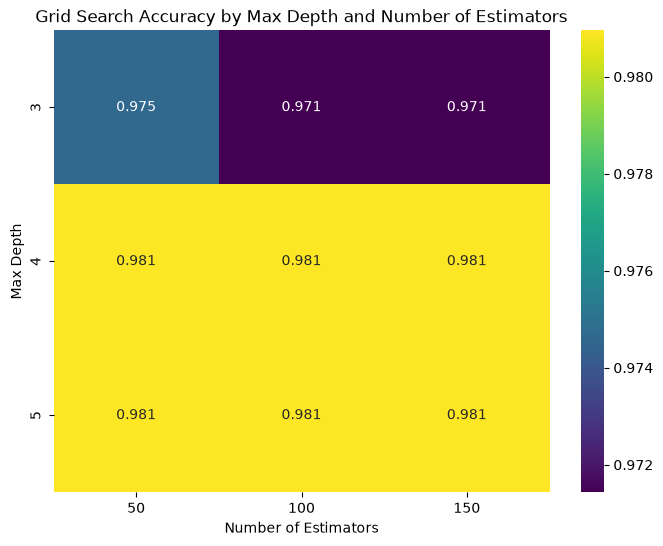

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(
    values='mean_test_score',
    index='param_max_depth',
    columns='param_n_estimators'
)

plt.figure(figsize=(8,6))
sns.heatmap(pivot_table, annot=True,
            fmt='.3f', cmap='viridis')
plt.title(
    'Grid Search Accuracy by Max Depth and Number of Estimators')
plt.xlabel('Number of Estimators')
plt.ylabel('Max Depth')
plt.show()

**Verification against the book:** Figure 8.7 shows 0.975 / 0.971 / 0.971 for `max_depth=3` and 0.981 for every other cell — reproduced ✔. The book reads this as: beyond `max_depth` 4 the accuracy no longer improves (and `n_estimators` hardly matters).

> **Book corrections for the heat-map.** (1) In the printed code the plot **title string is broken across two lines** inside the quotes — a `SyntaxError` when run as printed (fixed above). (2) The grid has **three** hyper-parameters, but the heat-map has two axes, and `pivot_table` silently **averages the CV score over the three `learning_rate` values**
> in every cell. Each cell is therefore a mean over learning rates (0.01, 0.1, 0.2), not the score of a model — the two views below separate them.

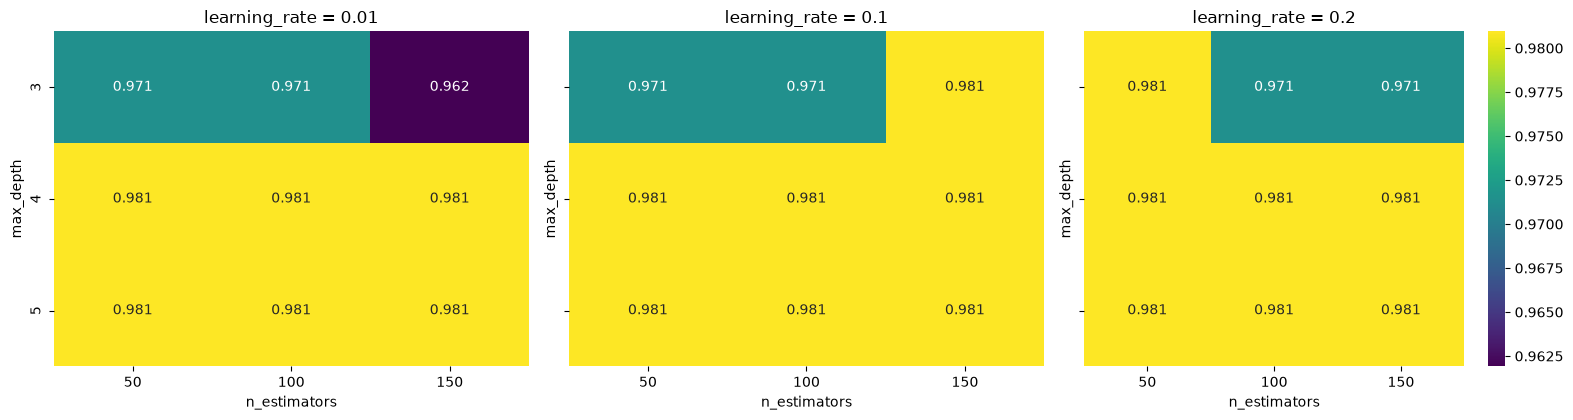

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, lr_ in zip(axes, (0.01, 0.1, 0.2)):
    sub_ = results[results["param_learning_rate"] == lr_]
    pv = sub_.pivot_table(values="mean_test_score", index="param_max_depth", columns="param_n_estimators")
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="viridis", vmin=results.mean_test_score.min(), vmax=results.mean_test_score.max(), ax=ax, cbar=ax is axes[-1])
    ax.set_title(f"learning_rate = {lr_}"); ax.set_xlabel("n_estimators"); ax.set_ylabel("max_depth")
plt.tight_layout(); plt.show()

Split by learning rate, the surface turns out to be **flat**: every cell with `max_depth` 4 or 5 scores 0.981 in all three panels — *even learning rate 0.01 with only 50 trees* (depth-4/5 trees fit quickly). Only the depth-3 cells vary (0.962–0.981, mostly 0.971), and the largest gap, 0.981 vs 0.962,
is **two training samples out of 105**. So the averaged heat-map does not hide any strong interaction here: the grid simply cannot discriminate, on a dataset where the CV score moves in steps of 0.0095 (one sample). (On a harder dataset the learning-rate × trees interaction from the previous section would show up clearly.)

**Extension — a validation curve for a random forest's `max_depth` and `n_estimators` (train vs validation, as the book recommends):**

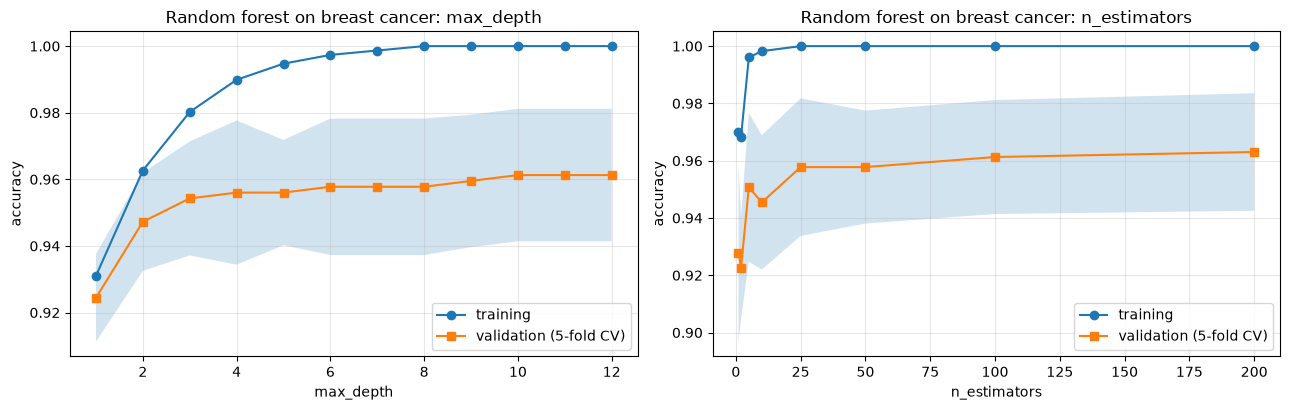

In [31]:
from sklearn.model_selection import validation_curve
from sklearn.ensemble import RandomForestClassifier

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, (pname, prange) in zip(ax, (("max_depth", np.arange(1, 13)), ("n_estimators", [1, 2, 5, 10, 25, 50, 100, 200]))):
    tr, te = validation_curve(RandomForestClassifier(n_estimators=100 if pname != "n_estimators" else 100, random_state=2024), Xb, yb, param_name=pname, param_range=prange, cv=cv)
    a.plot(prange, tr.mean(axis=1), "o-", label="training"); a.plot(prange, te.mean(axis=1), "s-", label="validation (5-fold CV)")
    a.fill_between(prange, te.mean(axis=1) - te.std(axis=1), te.mean(axis=1) + te.std(axis=1), alpha=.2); a.set_xlabel(pname); a.set_ylabel("accuracy"); a.grid(alpha=.3); a.legend()
    a.set_title(f"Random forest on breast cancer: {pname}")
plt.tight_layout(); plt.show()

For the forest, **depth** rises steadily from 0.925 (stumps) through 0.954 (depth 3) to ≈ 0.96 at depth 6–10 and then plateaus — **there is no decline at larger depth**: training accuracy reaches 1.0 at depth 8, yet validation does not fall, because averaging many deep trees cancels their individual overfitting
(this is the opposite of a single tree's behaviour). **More trees never hurt**: validation accuracy goes from 0.92–0.93 (1–2 trees) to ≈ 0.958 at 25–50 trees and 0.963 at 200, a slow, flat improvement with no overfitting — the property that makes forests easy to tune. (The shaded band, ± 1 sd across folds, is wider than all these differences.)

### Theory
* **Which hyper-parameters matter most:** trees — `max_depth`, `min_samples_leaf`; forests — `max_features`, `n_estimators` (more is better, until the plateau), `min_samples_leaf`; boosting — `learning_rate` × `n_estimators` (always tune together), `max_depth` (shallow, 3–5), `subsample`.
* **Search strategy:** coarse random search first (it explores more distinct values per parameter than a grid with the same budget), then a finer grid around the best region; use early stopping to set `n_estimators` for boosting.
* **Ties and noise:** when many configurations tie (as here) prefer the simplest/cheapest (the "one-standard-error rule"), and never read a 0.001 difference as meaningful.

### Hands-on workflow (from the book)
Dataset → split → define a parameter grid → `GridSearchCV`/`RandomizedSearchCV` → evaluate the best model on the test set → visualise the tuning results (done above).

## 5. Comparing ensemble methods

**Summary.** The three main ensemble strategies: **bagging** (reduces variance), **boosting** (reduces bias) and **stacking** (a meta-model learns how to combine several different base models).

### Getting ready

In [32]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…

In [33]:
rf_clf = RandomForestClassifier(
    n_estimators=100, random_state=2024
)
gb_clf = GradientBoostingClassifier(
    n_estimators=100, random_state=2024
)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('gb', gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5
)

rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')
print(f'Stacking Accuracy: {stacking_accuracy:.2f}')

Random Forest Accuracy: 0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy: 0.87


**Verification against the book:** it prints `Random Forest Accuracy: 0.91`, `Gradient Boosting Accuracy: 0.87`, `Stacking Accuracy: 0.87` — reproduced exactly ✔, and concludes "our random forest model outperforms both GBM and the stacked model".

### How it works… and the book's bar chart

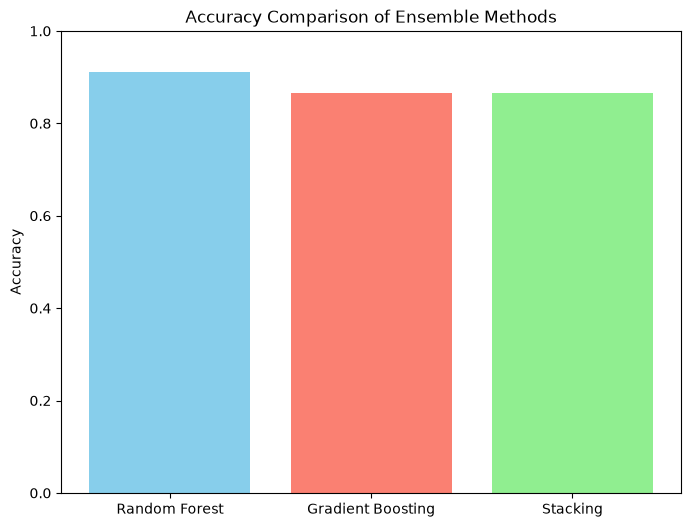

In [34]:
import matplotlib.pyplot as plt

methods = [
    'Random Forest', 'Gradient Boosting', 'Stacking'
]
accuracies = [
    rf_accuracy, gb_accuracy, stacking_accuracy
]

plt.figure(figsize=(8, 6))
plt.bar(methods, accuracies, color=['skyblue',
        'salmon', 'lightgreen'])
plt.title('Accuracy Comparison of Ensemble Methods')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

The bars look almost identical because the y-axis starts at 0 — and for good reason: 0.91 vs 0.87 is **4 vs 6 mistakes among 45 flowers**, a difference of two samples. **Can a ranking be read from that? Extension — repeated cross-validation on four datasets**
(bagging: random forest and extra-trees; boosting: gradient boosting and the histogram version; stacking; and a single tree for reference):

In [35]:
from sklearn.datasets import load_wine, load_digits
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.tree import DecisionTreeClassifier

datasets = {"Iris": load_iris(return_X_y=True), "Wine": load_wine(return_X_y=True), "Breast cancer": load_breast_cancer(return_X_y=True)}
def make_models():
    return {
        "Decision tree": DecisionTreeClassifier(random_state=2024),
        "Random forest": RandomForestClassifier(n_estimators=100, random_state=2024),
        "Extra-trees": ExtraTreesClassifier(n_estimators=100, random_state=2024),
        "Gradient boosting": GradientBoostingClassifier(n_estimators=100, random_state=2024),
        "HistGradientBoosting": HistGradientBoostingClassifier(random_state=2024),
        "Stacking (RF+GB -> LogReg)": StackingClassifier(estimators=[("rf", RandomForestClassifier(n_estimators=100, random_state=2024)), ("gb", GradientBoostingClassifier(n_estimators=100, random_state=2024))],
                                                         final_estimator=LogisticRegression(max_iter=2000), cv=3),
    }

rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
table = {}; times = {}
for dname, (Xd, yd) in datasets.items():
    for mname, m in make_models().items():
        r = cross_validate(m, Xd, yd, cv=rcv)
        table.setdefault(mname, {})[dname] = f"{r['test_score'].mean():.3f} ± {r['test_score'].std():.3f}"
        times.setdefault(mname, []).append(r["fit_time"].mean())
res = pd.DataFrame(table).T
res["mean fit time (s)"] = {k: round(np.mean(v), 2) for k, v in times.items()}
res

,Iris,Wine,Breast cancer,mean fit time (s)
Decision tree,0.956 ± 0.020,0.907 ± 0.031,0.934 ± 0.020,0.00
Random forest,0.953 ± 0.036,0.983 ± 0.017,0.960 ± 0.017,0.23
Extra-trees,0.953 ± 0.036,0.987 ± 0.017,0.969 ± 0.012,0.16
Gradient boosting,0.960 ± 0.028,0.937 ± 0.037,0.961 ± 0.017,0.42
HistGradientBoosting,0.949 ± 0.032,0.968 ± 0.027,0.965 ± 0.014,0.20
Stacking (RF+GB -> LogReg),0.962 ± 0.029,0.976 ± 0.028,0.964 ± 0.016,2.38


Reading the table (mean ± standard deviation of accuracy over 15 train/validation splits):
* **On Iris**, all six models are at 0.949–0.962 and the differences are **far smaller than the ± 0.03 spread**; the book's ranking (forest > boosting = stacking) cannot be distinguished from noise — and the **single decision tree (0.956) is right in the middle of the pack**, not behind.
* **On Wine** the picture is different: the bagging-type models (random forest 0.983, extra-trees 0.987) beat the single tree (0.907) by 8 points and the default gradient boosting (0.937) by ≈ 5 points — more than one standard deviation (0.017–0.037) — with HistGradientBoosting (0.968) and stacking (0.976) in between.
  So default boosting is not automatically better than a forest; on small data with a few informative features the forest's variance reduction wins.
* **On Breast cancer** every ensemble beats the single tree (0.934) by 2.6–3.5 points (0.960–0.969), and among themselves they are tied within one standard deviation.
* **No universal winner:** the order changes with the dataset (extra-trees/forest top on Wine and Breast cancer, stacking nominally top on Iris), and most gaps are inside the noise.
* **Stacking is the slowest** (≈ 1.8 s per fit vs 0.2–0.3 s for the others: it trains every base model on `cv` folds plus once more) and only *matches* its best base model here (Wine 0.976 vs 0.983; Breast cancer 0.964 vs 0.961); it pays off when the base models make *different* kinds of errors (e.g. trees with linear models or k-NN) — two tree ensembles are very similar.
* HistGradientBoosting is about twice as fast as the exact gradient-boosting model on these small datasets (0.16 s vs 0.33 s) and is competitive.

**Extension — what stacking actually does inside.** The meta-model is trained on **out-of-fold predictions** of the base models (so it never sees a base model's prediction on data that model was trained on), then base models are refitted on all the data:

In [36]:
from sklearn.model_selection import cross_val_predict

base = [("rf", RandomForestClassifier(n_estimators=100, random_state=2024)), ("gb", GradientBoostingClassifier(n_estimators=100, random_state=2024))]
meta_features = np.hstack([cross_val_predict(m, X_train, y_train, cv=5, method="predict_proba") for _, m in base])     # out-of-fold probabilities
print("meta-feature matrix:", meta_features.shape, "= (n_train, n_base_models x n_classes)")
meta = LogisticRegression(max_iter=2000).fit(meta_features, y_train)
fitted_base = [m.fit(X_train, y_train) for _, m in base]
manual_stack = meta.predict(np.hstack([m.predict_proba(X_test) for m in fitted_base]))
print("manual stacking accuracy:", round(accuracy_score(y_test, manual_stack), 4), "| StackingClassifier:", round(stacking_accuracy, 4))
print("same predictions as StackingClassifier:", (manual_stack == stacking_pred).all())
print("meta-model weight on each base model (rows=classes; columns = rf class0..2, gb class0..2):\n", meta.coef_.round(1))

meta-feature matrix: (105, 6) = (n_train, n_base_models x n_classes)


manual stacking accuracy: 0.8667 | StackingClassifier: 0.8667
same predictions as StackingClassifier: True
meta-model weight on each base model (rows=classes; columns = rf class0..2, gb class0..2):
 [[ 1.4 -0.7 -0.7  1.4 -0.6 -0.7]
 [-0.7  1.1 -0.4 -0.7  1.2 -0.5]
 [-0.6 -0.4  1.1 -0.6 -0.6  1.2]]


The manual version reproduces `StackingClassifier` (same recipe: out-of-fold class probabilities → logistic regression).

### There's more… (book)
Compare on more datasets and with more metrics (precision, recall, F1, ROC) — done above for datasets and accuracy; the same `cross_validate` call accepts `scoring=[...]` for several metrics at once.

### Theory
* **Bagging** (random forest, extra-trees): independent models on resampled data → averages out variance; needs low-bias base learners (deep trees); parallelisable; hard to overfit.
* **Boosting** (gradient boosting, AdaBoost): sequential, each model corrects the previous → reduces bias; shallow base learners; sensitive to noise and to hyper-parameters; more tuning.
* **Stacking:** heterogeneous base models + a meta-learner trained on out-of-fold predictions; can beat any single model if the base models are diverse; more complex and slower; risk of leakage if out-of-fold predictions are not used.
* **No free lunch:** differences of 1–2 test samples are noise — compare with repeated cross-validation, and prefer the simplest model that is statistically tied with the best.

### Hands-on workflow (from the book)
Several classification datasets → splits → train bagging, boosting and stacking classifiers → evaluate with several metrics → visualise the comparison (done above, with repeated CV).

## 6. Practical exercises with tree-based models

The book gives three exercises as step lists; here is my implementation of each.

### Exercise 1 — Build and evaluate a decision tree classifier (Breast Cancer)
Steps: libraries → data → split → create and train → predict → evaluate. A shallow tree so that the model can be read as a set of rules:

accuracy: 0.9357 | unconstrained tree: 0.9298
              precision    recall  f1-score   support

   malignant       0.91      0.92      0.91        64
      benign       0.95      0.94      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



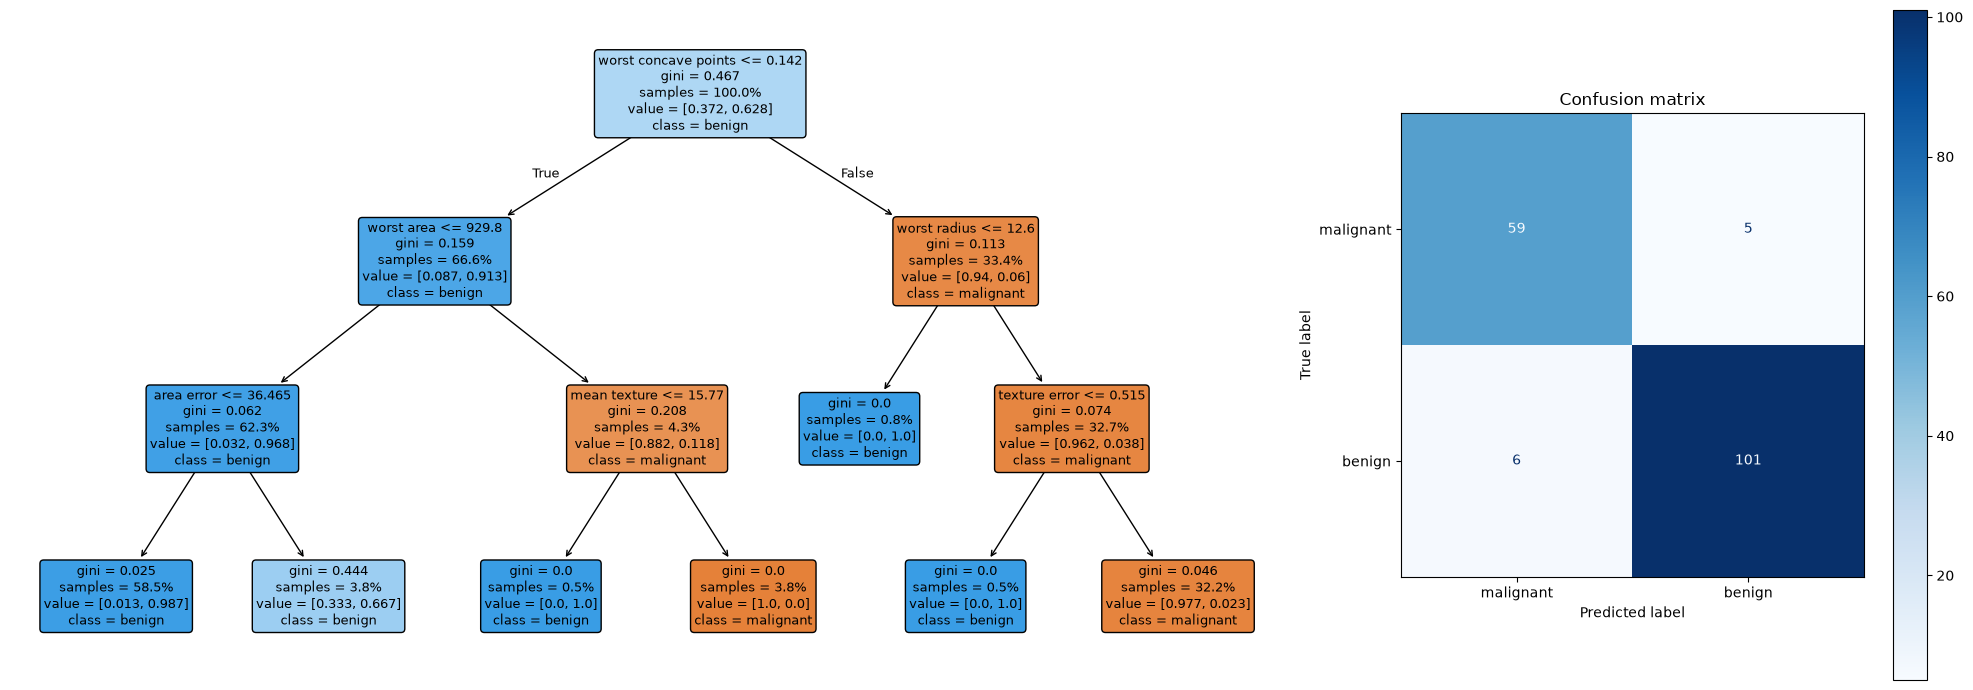

|--- worst concave points <= 0.14
|   |--- worst area <= 929.80
|   |   |--- area error <= 36.47
|   |   |   |--- class: 1
|   |   |--- area error >  36.47
|   |   |   |--- class: 1
|   |--- worst area >  929.80
|   |   |--- mean texture <= 15.77
|   |   |   |--- class: 1
|   |   |--- mean texture >  15.77
|   |   |   |--- class: 0
|--- worst concave points >  0.14
|   |--- worst radius <= 12.60
|   |   |--- class: 1
|   |--- worst radius >  12.60
|   |   |--- texture error <= 0.52
|   |   |   |--- class: 1
|   |   |--- texture error >  0.52
|   |   |   |--- class: 0



In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

Xb, yb = load_breast_cancer(return_X_y=True); bc_names = load_breast_cancer().feature_names
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=2024, stratify=yb)

tree3 = DecisionTreeClassifier(max_depth=3, random_state=2024).fit(Xb_tr, yb_tr)
pred = tree3.predict(Xb_te)
print("accuracy:", round(accuracy_score(yb_te, pred), 4), "| unconstrained tree:", round(DecisionTreeClassifier(random_state=2024).fit(Xb_tr, yb_tr).score(Xb_te, yb_te), 4))
print(classification_report(yb_te, pred, target_names=load_breast_cancer().target_names))

fig, ax = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(tree3, feature_names=bc_names, class_names=load_breast_cancer().target_names, filled=True, rounded=True, proportion=True, ax=ax[0], fontsize=9)
ConfusionMatrixDisplay.from_predictions(yb_te, pred, display_labels=load_breast_cancer().target_names, cmap="Blues", ax=ax[1]); ax[1].set_title("Confusion matrix")
plt.tight_layout(); plt.show()
print(export_text(tree3, feature_names=list(bc_names), max_depth=3))

A depth-3 tree reaches 0.936 test accuracy using six tests on a handful of measurements (`worst concave points`, `worst area`, `area error`, `mean texture`, `worst radius`, `texture error`) — a model a clinician can read — and is as accurate on the test set as the unconstrained tree (0.930; a difference of one test sample).
Each leaf is a plain rule, for example: *worst concave points ≤ 0.14 and worst area ≤ 930 → benign*.

### Exercise 2 — Tune a random forest with grid search (Wine)
Steps: libraries → data → split → define a grid and run the search → evaluate the best model.

combinations: 54 x 5 folds | tied for best CV score: 26
best parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 50}


CV accuracy 0.9837 | test accuracy 0.9815 | default forest test accuracy 0.9815
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.95      0.98        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



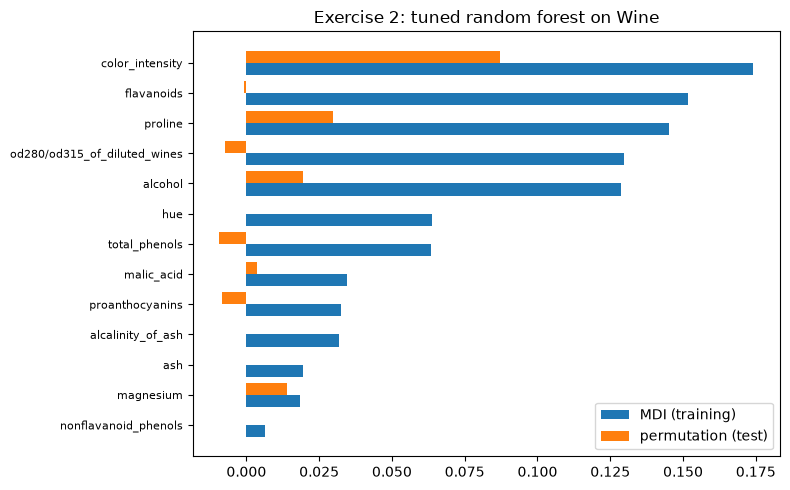

In [38]:
Xw, yw = load_wine(return_X_y=True); wine_names = load_wine().feature_names
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, random_state=2024, stratify=yw)

rf_grid = {"n_estimators": [50, 100, 200], "max_depth": [None, 3, 5], "max_features": ["sqrt", "log2", None], "min_samples_leaf": [1, 3]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=2024), rf_grid, cv=5, scoring="accuracy", n_jobs=1).fit(Xw_tr, yw_tr)
best_rf = gs_rf.best_estimator_; pred = best_rf.predict(Xw_te)
res = pd.DataFrame(gs_rf.cv_results_)
print("combinations:", len(res), "x 5 folds | tied for best CV score:", int((res.rank_test_score == 1).sum()))
print("best parameters:", gs_rf.best_params_)
print(f"CV accuracy {gs_rf.best_score_:.4f} | test accuracy {accuracy_score(yw_te, pred):.4f} | default forest test accuracy {RandomForestClassifier(random_state=2024).fit(Xw_tr, yw_tr).score(Xw_te, yw_te):.4f}")
print(classification_report(yw_te, pred, target_names=load_wine().target_names))

imp = pd.Series(best_rf.feature_importances_, index=wine_names).sort_values()
perm = pd.Series(permutation_importance(best_rf, Xw_te, yw_te, n_repeats=20, random_state=0).importances_mean, index=wine_names)[imp.index]
fig, ax = plt.subplots(figsize=(8, 5)); y_pos = np.arange(len(imp)); ax.barh(y_pos - .2, imp.values, .4, label="MDI (training)"); ax.barh(y_pos + .2, perm.values, .4, label="permutation (test)")
ax.set_yticks(y_pos); ax.set_yticklabels(imp.index, fontsize=8); ax.legend(); ax.set_title("Exercise 2: tuned random forest on Wine"); plt.tight_layout(); plt.show()

The tuned forest scores 0.9815 on the 54 test wines (one mistake), exactly the same as the *default* forest; 26 of the 54 configurations tie for the best CV score (0.9837), so the printed "best" is one of many equivalent choices — the point of the exercise is the workflow, and a lesson that tuning cannot improve a model that is already at the data's ceiling.
**The importance plot shows the two methods disagreeing:** by impurity (MDI) the top features are `color_intensity`, `flavanoids`, `proline`, `od280/od315` and `alcohol`; by permutation importance on the test set, `color_intensity` is clearly first (≈ 0.09), followed by `proline` and `alcohol`, while `flavanoids` ≈ 0 and `od280` is slightly negative.
The reason is correlation: `flavanoids`, `total_phenols` and `od280/od315` measure overlapping chemistry, so shuffling one leaves the others to compensate. Interpret importances of correlated features with care (the same effect as on Breast Cancer in Section 2).

### Exercise 3 — Compare gradient boosting and random forest (Digits)
Steps: libraries → data → split → create and train both → predict and evaluate. The 10-class digits data (1 797 images, 64 pixels) is a more demanding test than Iris:

,test accuracy,test log-loss,fit time (s)
model,,,
Random forest (200 trees),0.972,0.335,0.797
Gradient boosting (100 trees),0.965,0.142,7.194
HistGradientBoosting,0.963,0.145,2.134


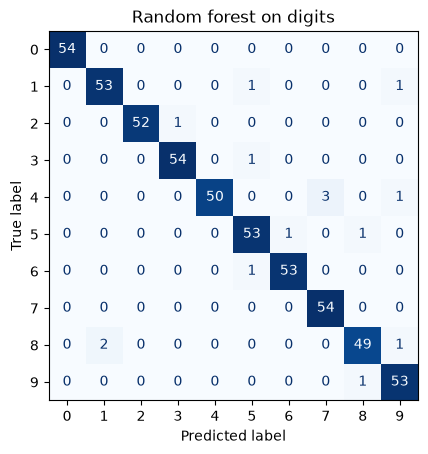

In [39]:
Xd, yd = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=2024, stratify=yd)

rows = []
for name, m in (("Random forest (200 trees)", RandomForestClassifier(n_estimators=200, random_state=2024)),
                ("Gradient boosting (100 trees)", GradientBoostingClassifier(n_estimators=100, random_state=2024)),
                ("HistGradientBoosting", HistGradientBoostingClassifier(random_state=2024))):
    t0 = time.time(); m.fit(Xd_tr, yd_tr); ft = time.time() - t0
    p = m.predict(Xd_te); proba = m.predict_proba(Xd_te)
    rows.append({"model": name, "test accuracy": accuracy_score(yd_te, p), "test log-loss": log_loss(yd_te, proba), "fit time (s)": ft})
display(pd.DataFrame(rows).set_index("model").round(3))
rf_d = RandomForestClassifier(n_estimators=200, random_state=2024).fit(Xd_tr, yd_tr)
ConfusionMatrixDisplay.from_estimator(rf_d, Xd_te, yd_te, cmap="Blues", colorbar=False); plt.title("Random forest on digits"); plt.show()

All three reach 0.963–0.972 accuracy on 540 test images (the forest nominally highest — a difference of 5 images). The boosted models have a much lower **log-loss** (0.14 vs 0.34): the forest's *averaged* probabilities are under-confident (a tree-average can never be as sharp as a boosted score), so the forest classifies as well but its probabilities are less reliable.
The forest is the simplest and fast (0.7 s); the exact `GradientBoostingClassifier` is by far the slowest (6.0 s: 10 classes × 100 trees), with `HistGradientBoosting` (1.7 s) in between.
As in Section 5, differences of a few test images are within noise; the answer to "which is better?" is *it depends on the data, the metric and the time budget*.

### Theory (for the exercises)
* **Readable models vs accurate models:** a shallow tree is a transparent rule set; forests/boosting trade that interpretability for accuracy (importances and permutation importances partly recover it).
* **Always tune with cross-validation and compare with repeated CV;** for tie-heavy results choose the simplest configuration.
* **Match the metric to the problem:** accuracy for balanced problems, log-loss when probabilities matter, recall for rare-event detection (Chapters 4 and 6).

## Chapter takeaways
1. A **decision tree** greedily picks the (feature, threshold) that most reduces impurity (Gini or entropy), recursively. It is interpretable and needs no scaling, but is **high-variance**: unconstrained, it memorises the training data. Control it with `max_depth`, `min_samples_*`, `min_impurity_decrease` or `ccp_alpha`, chosen by CV.
2. **Random forests** = bagging + random feature subsets: many decorrelated trees averaged (by probability) → much lower variance, little tuning, no overfitting from adding trees, a free **out-of-bag** estimate. Feature importances need care: the built-in impurity importance (MDI) slightly rewards noise, permutation importance understates *correlated* features (Breast Cancer, Wine) — compare both.
3. **Gradient boosting** adds shallow trees one at a time, each fitted to the current residuals (the negative gradient of the loss). It reduces bias; `learning_rate` and `n_estimators` trade off, and **early stopping** (`n_iter_no_change`) picks the number of trees. `HistGradientBoosting*` is the fast modern choice.
4. **Tuning:** many configurations tie on easy data (20 of 27 here) — the "best" parameters are arbitrary among equals; `RandomizedSearchCV` samples *independently* (it does not adapt); a heat-map of two parameters hides the others unless you slice by them.
5. **Comparing ensembles:** bagging reduces variance, boosting bias, stacking combines diverse models. On a 45-sample test set a 2-sample gap is noise; repeated cross-validation shows the ensembles beat a single tree clearly on Wine (+8 points for the forests) and Breast Cancer (+3), but **not at all on Iris**, and mostly tied among themselves, with no universal winner (default boosting was ≈ 5 points *behind* the forest on Wine).

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Gini impurity | range 0.0–1.0, "1.0 = even balance of all classes" | $1-\sum p_k^2$ has maximum $1-1/K$ (0.667 for 3 classes); never 1.0 |
| `plot_tree` | code uses defaults but text/figure show proportions (`samples = 100.0%`, rounded boxes) | defaults show counts; the figure needs `proportion=True, rounded=True` |
| Categorical data | trees handle "numerical and categorical data" | `DecisionTreeClassifier` needs numeric input; native categorical support only in `HistGradientBoosting*` |
| Random forest voting | "majority vote or average of predictions" | scikit-learn averages class probabilities (soft voting) |
| RF vs tree comparison | 0.867 → 0.911 on one split as evidence the forest "improves quite a bit" | a 2-sample difference on 45 flowers; repeated CV shows **no gain** on Iris (0.956 vs 0.953) and a real one on Wine (+8) and Breast Cancer (+3) |
| GBM = tree result | "overfitting … reached a local maximum" | both fit the training set perfectly and make the same 6 hard test errors; "local maximum" is the wrong concept; multiclass GBM trains one tree per class per iteration |
| Early stopping | described with tree constraints (`max_depth`…) | that is pre-pruning; early stopping halts *boosting iterations* using a validation score (`n_iter_no_change`) |
| `RandomizedSearchCV` | "adjusts those hyperparameters with each additional iteration" | draws configurations independently at random; no adaptation (that is Bayesian optimisation) |
| Grid-search "best" | reports `lr=0.01, depth=4, n=50` as best | 20 of 27 configurations tie at the top; the reported one is just the first |
| Heat-map | two-parameter heat-map of a three-parameter grid | `pivot_table` averages over `learning_rate`; title string also broken across lines (`SyntaxError`) |
| Ensemble ranking | "random forest outperforms both GBM and stacking" | 4 vs 6 mistakes of 45; not distinguishable on Iris (repeated CV: all 0.95–0.96); on other datasets the order differs (forests beat default boosting on Wine) |
| Root split | root is `petal width <= 0.8` as if it were *the* best split | `petal length <= 2.5` ties it exactly (both isolate setosa); scikit-learn breaks the tie randomly (`random_state`) |
| Tree growth | implied: constraining the tree is needed for good accuracy | on Breast Cancer the unconstrained tree has the highest CV accuracy (0.940); limits mainly buy simplicity (6–11 leaves vs 22) |
| Imports | `classification_report` (and matplotlib) missing from some recipes' imports | added |

*All eight chapters requested so far are complete.*